# ConnectaTel: uso móvil, calidad de datos y segmentación

**José Luis Ronquillo Quintanar | TripleTen, Sprint 7 | Proyecto 6**

Proyecto educativo desarrollado con asistencia de IA. El análisis integra planes, usuarios y eventos para describir el uso móvil, revisar extremos y proponer oportunidades comerciales.

**Alcance:** el corte del curso es 2024, pero la actividad disponible abarca únicamente enero-junio de 2024. Se distinguen eventos, usuarios y meses con actividad observada. No se atribuye fraude, rentabilidad ni causalidad a las diferencias descriptivas.

Los originales se conservan. Las reglas, exclusiones e imputaciones se documentan. La versión pública muestra resultados agregados y omite las salidas con registros individuales.

## 1. Carga y exploración

Se importan las herramientas y se cargan los tres archivos autorizados.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

sns.set_theme(style='whitegrid', context='notebook')
PALETA = {'Basico': '#287C8E', 'Premium': '#D08B42'}
columnas_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
columnas_numericas = ['age'] + columnas_uso


In [2]:
# Buscar una copia autorizada del curso; no descargar ni publicar registros.
candidatas = [Path('/datasets'), Path('data'), Path('../data')]
DATA = next((p for p in candidatas if all((p/f).exists() for f in
             ['plans.csv', 'users_latam.csv', 'usage.csv'])), None)
if DATA is None:
    raise FileNotFoundError('Coloca los tres CSV del curso en data/ y reinicia el notebook.')
plans = pd.read_csv(DATA/'plans.csv')
users = pd.read_csv(DATA/'users_latam.csv')
usage = pd.read_csv(DATA/'usage.csv')
plans_original = plans.copy(deep=True)
users_original = users.copy(deep=True)
usage_original = usage.copy(deep=True)


In [3]:
display(plans.head())

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
display(users.head())

Vista de registros individuales omitida en la publicación. Ejecútala solo con una copia autorizada de los datos.


In [5]:
display(usage.head())

Vista de registros individuales omitida en la publicación. Ejecútala solo con una copia autorizada de los datos.


Las primeras filas sirven para revisar estructura. Sus salidas se omiten de la versión pública para no publicar registros individuales.

### Estructura, duplicados y claves

Se verifica la unicidad de usuarios, eventos y planes, y la correspondencia de las relaciones antes de unir tablas.

In [6]:
for nombre, df in [('plans', plans), ('users', users), ('usage', usage)]:
    print(nombre, df.shape, '| duplicados exactos:', df.duplicated().sum())
assert users['user_id'].is_unique and usage['id'].is_unique
assert plans['plan_name'].is_unique
assert usage['user_id'].isin(users['user_id']).all()
assert users['plan'].isin(plans['plan_name']).all()
print('Claves y relaciones comprobadas.')

plans (2, 8) | duplicados exactos: 0
users (4000, 8) | duplicados exactos: 0
usage (40000, 6) | duplicados exactos: 0
Claves y relaciones comprobadas.


In [7]:
plans.info()

<class 'pandas.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      str    
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), str(1)
memory usage: 260.0 bytes


In [8]:
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     4000 non-null   int64
 1   first_name  4000 non-null   str  
 2   last_name   4000 non-null   str  
 3   age         4000 non-null   int64
 4   city        3531 non-null   str  
 5   reg_date    4000 non-null   str  
 6   plan        4000 non-null   str  
 7   churn_date  466 non-null    str  
dtypes: int64(2), str(6)
memory usage: 250.1 KB


In [9]:
usage.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  str    
 3   date      39950 non-null  str    
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), str(2)
memory usage: 1.8 MB


## 2. Calidad de datos

### Valores ausentes

Los porcentajes se calculan sobre cada tabla. La decisión de imputar depende del significado del campo, no solo del porcentaje de nulos.

In [10]:
display(pd.DataFrame({'Ausentes': users.isna().sum(),
    'Porcentaje': users.isna().mean().mul(100).round(3)}))

,Ausentes,Porcentaje
user_id,0,0.000
first_name,0,0.000
last_name,0,0.000
age,0,0.000
city,469,11.725
reg_date,0,0.000
plan,0,0.000
churn_date,3534,88.350


In [11]:
display(pd.DataFrame({'Ausentes': usage.isna().sum(),
    'Porcentaje': usage.isna().mean().mul(100).round(3)}))

,Ausentes,Porcentaje
id,0,0.000
user_id,0,0.000
type,0,0.000
date,50,0.125
duration,22076,55.190
length,17896,44.740


La ciudad falta en 469 usuarios (11.725%). Se conserva como desconocida, sin inventar ubicaciones. La baja está ausente en 3,534 usuarios (88.35%); la ausencia por sí sola no demuestra que un cliente siga activo.

En eventos, hay 50 fechas ausentes (0.125%). `duration` tiene 22,076 nulos (55.19%) y `length`, 17,896 (44.74%). Sus proporciones se investigan por tipo de evento antes de imputar.

### Valores inválidos y categorías

Se revisan rangos numéricos y categorías relevantes. Los identificadores sirven como claves, no como medidas de comportamiento.

In [12]:
display(users[['user_id','age']].describe())

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


`user_id` identifica 4,000 usuarios únicos. La edad contiene 55 valores `-999` (1.375%), incompatibles con una edad. Se reemplazan después de excluirlos del cálculo de la mediana.

In [13]:
display(usage[['id','user_id','duration','length']].describe())

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


Hay 40,000 identificadores de evento únicos y 3,999 usuarios con al menos un registro en el origen. La duración máxima registrada es 120 minutos y la longitud máxima, 1,490; estos extremos requieren revisión, pero no son prueba de error o fraude. Se conserva la duración cero como llamada registrada sin minutos.

In [14]:
for col in ['city','plan']:
    print(col)
    display(users[col].value_counts(dropna=False).to_frame('Usuarios'))

city
plan


,Usuarios
city,
Bogotá,808
CDMX,730
Medellín,616
NaN,469
GDL,450
Cali,424
MTY,407
?,96


,Usuarios
plan,
Basico,2595
Premium,1405


La ciudad incluye 96 marcadores `?` (2.4%); junto con los 469 ausentes, quedan 565 ciudades sin determinar (14.125%). Los planes son Básico y Premium. No se imputan ciudades a partir del nombre o apellido.

In [15]:
display(usage['type'].value_counts(dropna=False).to_frame('Eventos'))

,Eventos
type,
text,22092
call,17908


El origen contiene 17,908 llamadas y 22,092 mensajes. Para las métricas temporales se separan después los 50 eventos sin fecha.

Se corrigen las edades centinela, los marcadores de ciudad y las altas posteriores al corte. Los campos impropios del tipo de evento también se señalan: 16 mensajes contienen duración y 12 llamadas contienen longitud. Los minutos se suman exclusivamente en llamadas.

### Fechas y corte temporal

Se convierten con `errors="coerce"`, conservando el original para auditar. No se supone una codificación no documentada para la fecha de baja.

In [16]:
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')
# La baja se conserva en su formato original; no se adivina la unidad temporal.
users['churn_date_raw'] = users['churn_date'].copy()
users['churn_date'] = pd.to_datetime(users['churn_date_raw'], format='%Y-%m-%d', errors='coerce')
users['churn_parse_error'] = users['churn_date_raw'].notna() & users['churn_date'].isna()
print('Bajas con formato no interpretable:', users['churn_parse_error'].sum())

Bajas con formato no interpretable: 466


In [17]:
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:
display(users['reg_date'].dt.year.value_counts(dropna=False).sort_index().to_frame('Usuarios'))

,Usuarios
reg_date,
2022,1314
2023,1316
2024,1330
2026,40


Las altas incluyen 40 registros de 2026 (1%), posteriores al corte de 2024 del ejercicio. Se marcan como nulas y se conserva una bandera; no se eliminan los usuarios.

In [19]:
display(usage['date'].dt.year.value_counts(dropna=False).sort_index().to_frame('Eventos'))

,Eventos
date,
2024.0,39950
NaN,50


Los eventos con fecha abarcan del 1 de enero al 30 de junio de 2024. Los 50 sin fecha se apartan del análisis temporal, conservándose para una comparación de sensibilidad.

Las 466 bajas no vacías están representadas con notación científica y coma decimal, no con una fecha directamente interpretable. Su unidad y precisión requieren confirmar el diccionario de datos. No se estiman tasas de abandono ni retención usando esas fechas.

## 3. Limpieza

Se imputa la mediana calculada solo con edades válidas, se reemplaza `?` por un ausente y se marca el alta fuera de periodo. Cada cambio conserva su indicador.

In [20]:
users['age_invalid_flag'] = users['age'].eq(-999) | ~users['age'].between(0,120)
age_mediana = users.loc[~users['age_invalid_flag'],'age'].median()
users.loc[users['age_invalid_flag'],'age'] = age_mediana
print('Mediana de edades válidas:', age_mediana)
print('Edades imputadas:', users['age_invalid_flag'].sum())
display(users['age'].describe())

Mediana de edades válidas: 48.0
Edades imputadas: 55


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
users['city'] = users['city'].astype('string').str.strip().replace({'?':pd.NA,'':pd.NA})
users['city_missing_flag'] = users['city'].isna()
# País inferido por ciudad, no nacionalidad ni ubicación confirmada.
mapa_pais = {'CDMX':'México','GDL':'México','MTY':'México',
             'Bogotá':'Colombia','Medellín':'Colombia','Cali':'Colombia'}
users['pais_inferido'] = users['city'].map(mapa_pais).fillna('Sin determinar')
print('Ciudades sin determinar:', users['city'].isna().sum())
display(users['pais_inferido'].value_counts().to_frame('Usuarios'))

Ciudades sin determinar: 565


,Usuarios
pais_inferido,
Colombia,1848
México,1587
Sin determinar,565


In [22]:
users['reg_date_original'] = users['reg_date'].copy()
users['reg_date_invalid_flag'] = users['reg_date'].gt(pd.Timestamp('2024-12-31 23:59:59'))
users.loc[users['reg_date_invalid_flag'],'reg_date'] = pd.NaT
print('Altas fuera del periodo marcadas como nulas:', users['reg_date_invalid_flag'].sum())
display(users['reg_date'].dt.year.value_counts(dropna=False).sort_index().to_frame('Usuarios'))

Altas fuera del periodo marcadas como nulas: 40


,Usuarios
reg_date,
2022.0,1314
2023.0,1316
2024.0,1330
NaN,40


### Ausentes según tipo de evento

Se revisa la relación entre `type` y las dos medidas. Un dato que no aplica a un evento no requiere imputación numérica.

In [23]:
display(usage.groupby('type')['duration'].agg(
    eventos='size', ausentes=lambda s:s.isna().sum(),
    porcentaje_ausente=lambda s:100*s.isna().mean()).round(3))

,eventos,ausentes,porcentaje_ausente
type,,,
call,17908,0,0.000
text,22092,22076,99.928


In [24]:
display(usage.groupby('type')['length'].agg(
    eventos='size', ausentes=lambda s:s.isna().sum(),
    porcentaje_ausente=lambda s:100*s.isna().mean()).round(3))

,eventos,ausentes,porcentaje_ausente
type,,,
call,17908,17896,99.933
text,22092,0,0.000


La duración está presente en todas las llamadas y falta en 22,076 de los 22,092 mensajes. La longitud está presente en todos los mensajes y falta en 17,896 de las 17,908 llamadas.

Estos son principalmente **ausentes estructurales**: una llamada no tiene longitud de mensaje y un mensaje no tiene minutos de llamada. La asociación con `type` es observable; no demuestra por sí sola un mecanismo causal MAR. Se mantienen como nulos y se corrigen los 28 campos que no aplican, preservando banderas.

## 4. Perfil de uso por usuario

Se agregan mensajes, llamadas y minutos de los eventos fechados de 2024. La unión izquierda conserva a todos los usuarios; cero significa ausencia de eventos registrados en esta extracción, no ausencia demostrada de uso real.

In [25]:
# Corregir campos que no corresponden al tipo de evento y conservar banderas.
usage['duration_in_text_flag'] = usage['type'].eq('text') & usage['duration'].notna()
usage['length_in_call_flag'] = usage['type'].eq('call') & usage['length'].notna()
usage.loc[usage['type'].eq('text'),'duration'] = np.nan
usage.loc[usage['type'].eq('call'),'length'] = np.nan
assert usage.loc[usage['type'].eq('call'),'duration'].ge(0).all()
assert usage.loc[usage['type'].eq('text'),'length'].ge(0).all()

# Se apartan 50 eventos sin fecha del análisis temporal, sin borrarlos del origen.
usage_sin_fecha = usage.loc[usage['date'].isna()].copy()
usage_2024 = usage.loc[usage['date'].dt.year.eq(2024)].copy()
usage_2024['is_text'] = usage_2024['type'].eq('text').astype(int)
usage_2024['is_call'] = usage_2024['type'].eq('call').astype(int)
usage_agg = usage_2024.groupby('user_id').agg(
    mensajes=('is_text','sum'), llamadas=('is_call','sum'),
    minutos=('duration','sum')).reset_index()
print('Eventos fechados de 2024:', len(usage_2024), '| sin fecha:', len(usage_sin_fecha))
print('Periodo observado:', usage_2024['date'].min(), 'a', usage_2024['date'].max())
display(usage_agg.head(3))

Vista de registros individuales omitida en la publicación. Ejecútala solo con una copia autorizada de los datos.


In [26]:
usage_agg = usage_agg.rename(columns={'mensajes':'cant_mensajes',
    'llamadas':'cant_llamadas','minutos':'cant_minutos_llamada'})
display(usage_agg.head(3))

Vista de registros individuales omitida en la publicación. Ejecútala solo con una copia autorizada de los datos.


In [27]:
# Left join: conservar los 4,000 usuarios, incluido quien no registra actividad.
user_profile = users.merge(usage_agg,on='user_id',how='left',validate='one_to_one')
user_profile[columnas_uso] = user_profile[columnas_uso].fillna(0)
for col in ['cant_mensajes','cant_llamadas']:
    user_profile[col] = user_profile[col].astype(int)
user_profile = user_profile.merge(plans, left_on='plan',right_on='plan_name',
    how='left',validate='many_to_one')
assert len(user_profile)==len(users_original)==4000
assert user_profile['user_id'].is_unique
assert user_profile['cant_mensajes'].sum()==usage_2024['is_text'].sum()
assert user_profile['cant_llamadas'].sum()==usage_2024['is_call'].sum()
assert np.isclose(user_profile['cant_minutos_llamada'].sum(),
                  usage_2024.loc[usage_2024['type'].eq('call'),'duration'].sum())
display(user_profile.head(5))

Vista de registros individuales omitida en la publicación. Ejecútala solo con una copia autorizada de los datos.


### Estadísticas por usuario y tipo de plan

Los totales corresponden al periodo observado. La comparación usa también medias y medianas para evitar que el tamaño desigual de los planes domine la lectura.

In [28]:
display(user_profile[columnas_numericas].describe().round(3))
resumen_plan = user_profile.groupby('plan')[columnas_numericas].agg(['count','mean','median','std'])
display(resumen_plan.round(3))

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000,4000.000,4000.000,4000.000
mean,48.136,5.517,4.470,22.803
std,17.690,2.359,2.144,16.584
min,18.000,0.000,0.000,0.000
25%,33.000,4.000,3.000,11.000
50%,48.000,5.000,4.000,19.730
75%,63.000,7.000,6.000,31.180
max,79.000,17.000,15.000,155.690


age                        cant_mensajes                      cant_llamadas                      cant_minutos_llamada                      
        count    mean median     std         count   mean median    std         count   mean median    std                count    mean median    std
plan                                                                                                                                                 
Basico   2595  48.042   48.0  17.537          2595  5.519    5.0  2.363          2595  4.449    4.0  2.170                 2595  22.554  19.51  16.53
Premium  1405  48.310   48.0  17.973          1405  5.514    5.0  2.353          1405  4.510    4.0  2.095                 1405  23.264  20.30  16.68

In [29]:
display(user_profile['plan'].value_counts(normalize=True).mul(100).round(3).to_frame('Porcentaje'))

,Porcentaje
plan,
Basico,64.875
Premium,35.125


## 5. Distribuciones y valores atípicos

Los histogramas cubren el rango completo y normalizan cada plan por separado (`common_norm=False`). Así se compara la forma pese a que Básico reúne más usuarios.

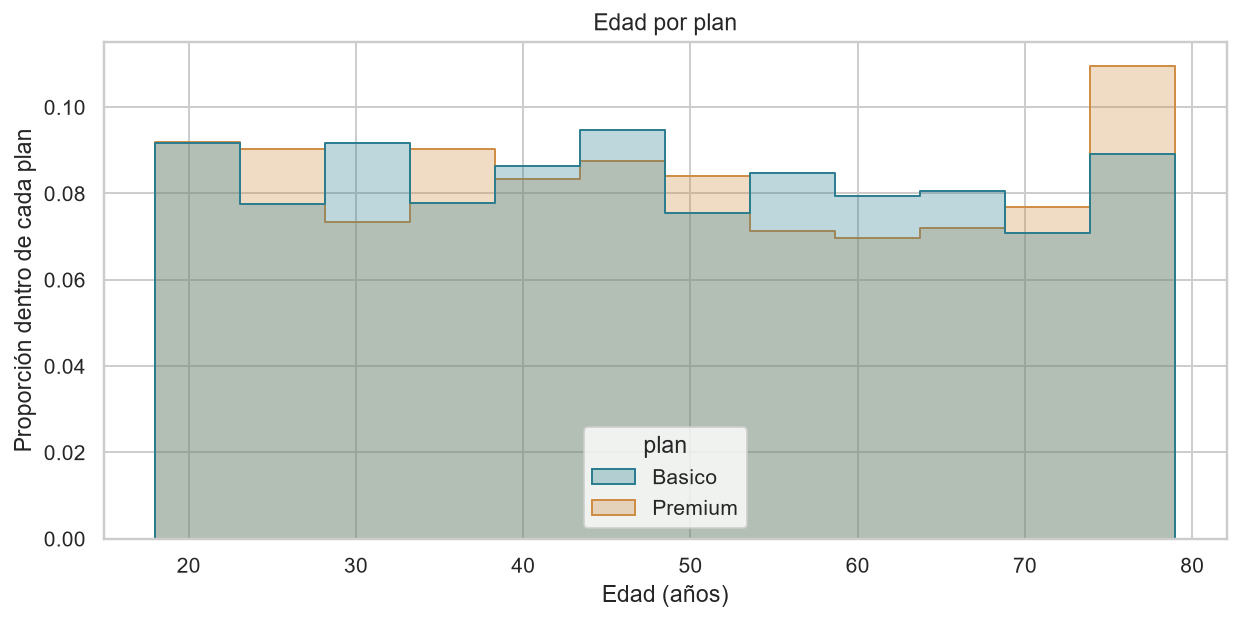

,count,mean,median,std,skew
plan,,,,,
Basico,2595,48.042,48.0,17.537,0.036
Premium,1405,48.310,48.0,17.973,0.066


In [30]:
fig, ax = plt.subplots(figsize=(9,4.6))
sns.histplot(data=user_profile,x='age',hue='plan',palette=PALETA,
    stat='probability',common_norm=False,binwidth=5,element='step',
    alpha=.30,ax=ax)
ax.set(title='Edad por plan',xlabel='Edad (años)',ylabel='Proporción dentro de cada plan')
plt.tight_layout(); plt.show()
display(user_profile.groupby('plan')['age'].agg(['count','mean','median','std','skew']).round(3))

**Lectura del gráfico de edad:** Basico: media 48.04, mediana 48.00 y asimetría 0.04. Premium: media 48.31, mediana 48.00 y asimetría 0.07. El histograma muestra frecuencias relativamente similares a lo largo del rango y asimetría cercana a cero, sin una concentración central propia de una campana. Incluye 55 imputaciones de 48 años; no se interpretan como edades confirmadas.

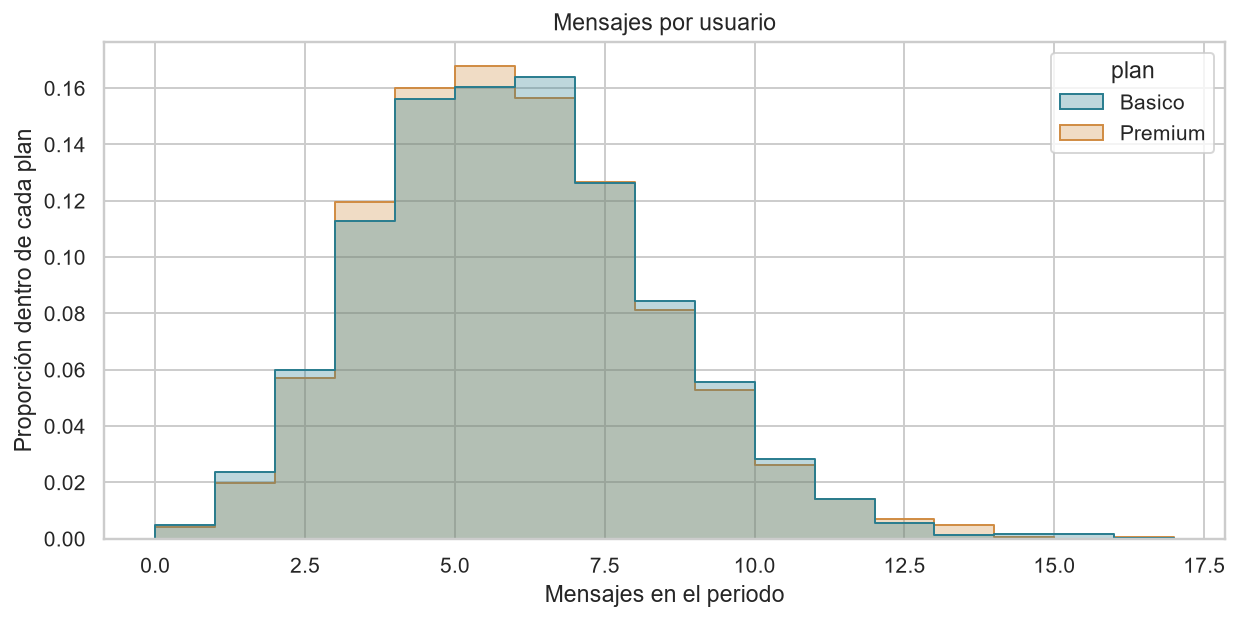

,count,mean,median,std,skew
plan,,,,,
Basico,2595,5.519,5.0,2.363,0.436
Premium,1405,5.514,5.0,2.353,0.495


In [31]:
fig, ax = plt.subplots(figsize=(9,4.6))
sns.histplot(data=user_profile,x='cant_mensajes',hue='plan',palette=PALETA,
    stat='probability',common_norm=False,binwidth=1,element='step',
    alpha=.30,ax=ax)
ax.set(title='Mensajes por usuario',xlabel='Mensajes en el periodo',ylabel='Proporción dentro de cada plan')
plt.tight_layout(); plt.show()
display(user_profile.groupby('plan')['cant_mensajes'].agg(['count','mean','median','std','skew']).round(3))

**Lectura del gráfico de mensajes:** Basico: media 5.52, mediana 5.00 y asimetría 0.44. Premium: media 5.51, mediana 5.00 y asimetría 0.49. En ambos planes se observa asimetría positiva y una cola hacia la derecha, más marcada en los minutos. Las diferencias entre planes se describen con estos valores; no se atribuyen al efecto causal del plan.

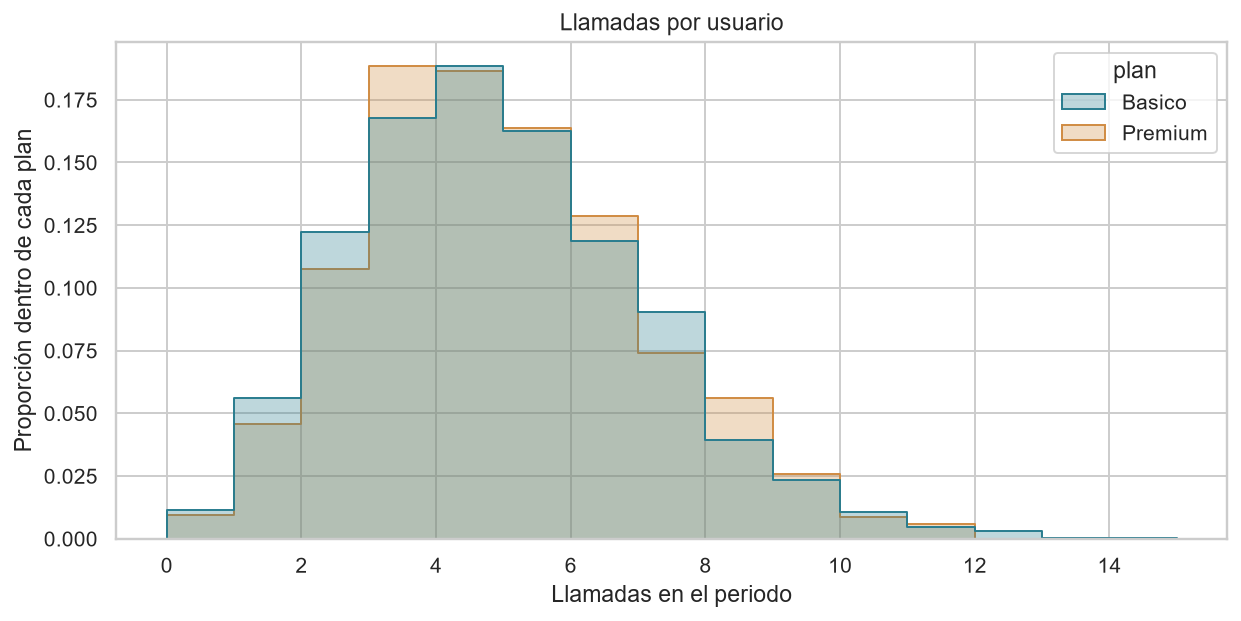

,count,mean,median,std,skew
plan,,,,,
Basico,2595,4.449,4.0,2.170,0.536
Premium,1405,4.510,4.0,2.095,0.443


In [32]:
fig, ax = plt.subplots(figsize=(9,4.6))
sns.histplot(data=user_profile,x='cant_llamadas',hue='plan',palette=PALETA,
    stat='probability',common_norm=False,binwidth=1,element='step',
    alpha=.30,ax=ax)
ax.set(title='Llamadas por usuario',xlabel='Llamadas en el periodo',ylabel='Proporción dentro de cada plan')
plt.tight_layout(); plt.show()
display(user_profile.groupby('plan')['cant_llamadas'].agg(['count','mean','median','std','skew']).round(3))

**Lectura del gráfico de llamadas:** Basico: media 4.45, mediana 4.00 y asimetría 0.54. Premium: media 4.51, mediana 4.00 y asimetría 0.44. En ambos planes se observa asimetría positiva y una cola hacia la derecha, más marcada en los minutos. Las diferencias entre planes se describen con estos valores; no se atribuyen al efecto causal del plan.

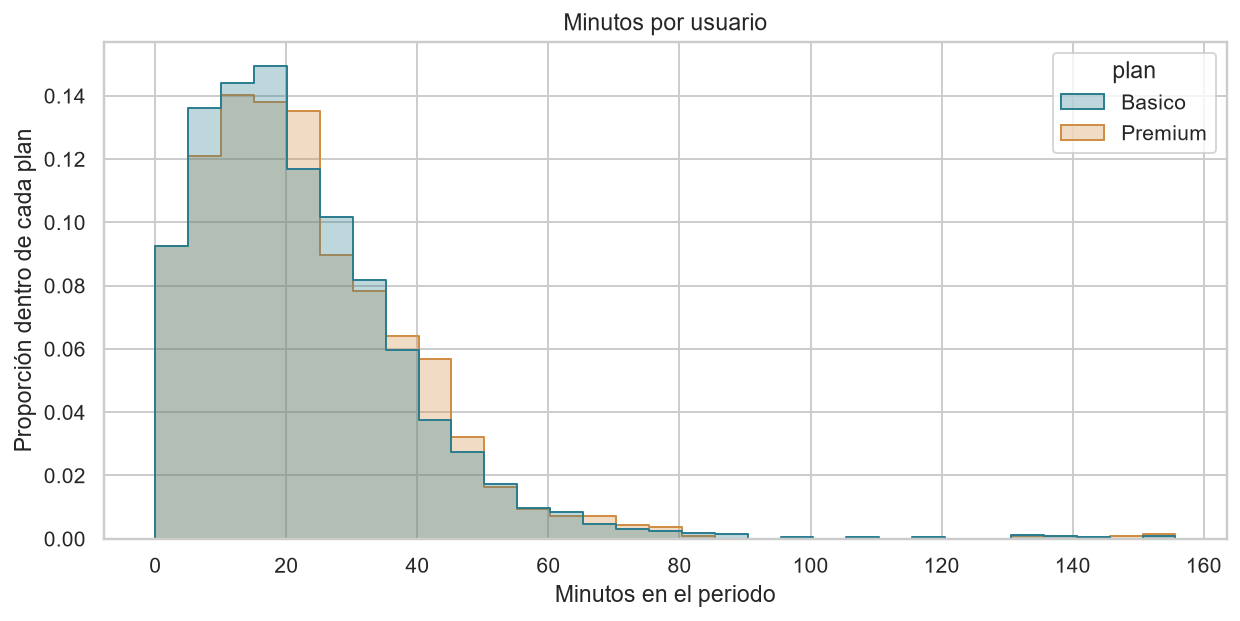

,count,mean,median,std,skew
plan,,,,,
Basico,2595,22.554,19.51,16.53,1.992
Premium,1405,23.264,20.30,16.68,1.990


In [33]:
fig, ax = plt.subplots(figsize=(9,4.6))
sns.histplot(data=user_profile,x='cant_minutos_llamada',hue='plan',palette=PALETA,
    stat='probability',common_norm=False,binwidth=5,element='step',
    alpha=.30,ax=ax)
ax.set(title='Minutos por usuario',xlabel='Minutos en el periodo',ylabel='Proporción dentro de cada plan')
plt.tight_layout(); plt.show()
display(user_profile.groupby('plan')['cant_minutos_llamada'].agg(['count','mean','median','std','skew']).round(3))

**Lectura del gráfico de minutos:** Basico: media 22.55, mediana 19.51 y asimetría 1.99. Premium: media 23.26, mediana 20.30 y asimetría 1.99. En ambos planes se observa asimetría positiva y una cola hacia la derecha, más marcada en los minutos. Las diferencias entre planes se describen con estos valores; no se atribuyen al efecto causal del plan.

### Boxplots y límites IQR

Los boxplots se muestran por plan. La tabla de límites y conteos IQR usa el conjunto completo de 4,000 usuarios. Se calculan ambos límites y se cuentan las observaciones señaladas. Los extremos se conservan en los indicadores originales.

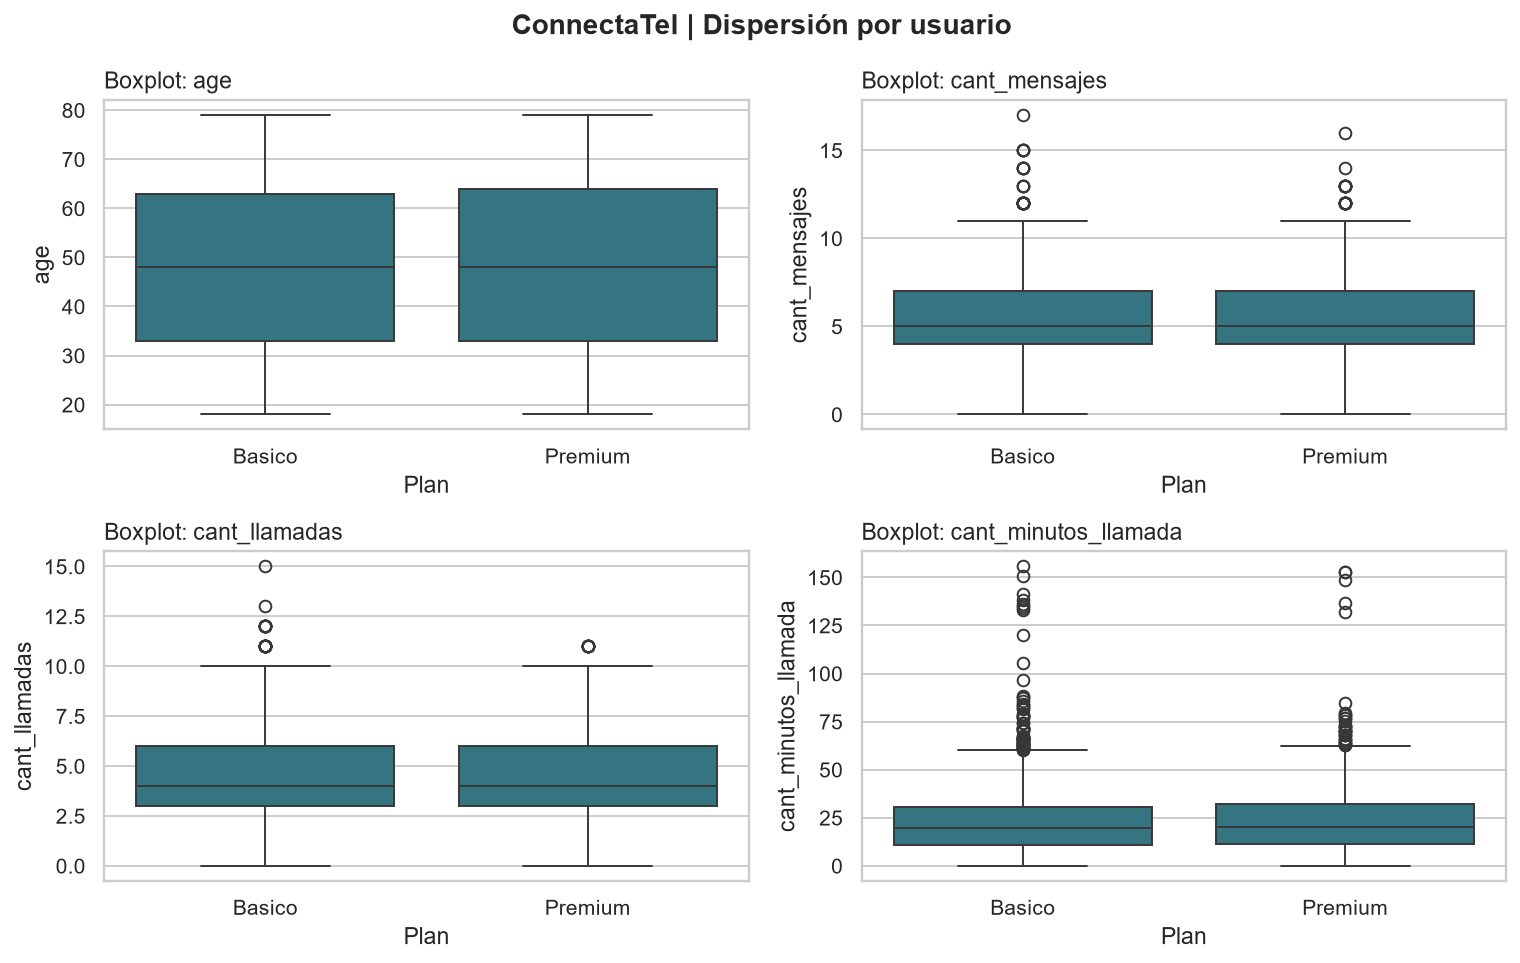

In [34]:
fig, axes = plt.subplots(2,2,figsize=(11,7))
for ax, col in zip(axes.flat,columnas_numericas):
    sns.boxplot(data=user_profile,x='plan',y=col,color='#287C8E',ax=ax)
    ax.set_title('Boxplot: '+col,loc='left')
    ax.set_xlabel('Plan'); ax.set_ylabel(col)
fig.suptitle('ConnectaTel | Dispersión por usuario',fontweight='bold')
plt.tight_layout(); plt.show()

**Valores señalados por IQR:**

- `age`: 0 usuarios (0.00%). Límite superior: 108.00.
- `cant_mensajes`: 45 usuarios (1.12%). Límite superior: 11.50.
- `cant_llamadas`: 30 usuarios (0.75%). Límite superior: 10.50.
- `cant_minutos_llamada`: 94 usuarios (2.35%). Límite superior: 61.45.

In [35]:
filas_iqr = []
for col in columnas_numericas:
    q1,q3 = user_profile[col].quantile([.25,.75])
    iqr = q3-q1
    inferior,superior = q1-1.5*iqr,q3+1.5*iqr
    flag = user_profile[col].lt(inferior) | user_profile[col].gt(superior)
    user_profile[col+'_outlier_iqr'] = flag
    filas_iqr.append({'variable':col,'Q1':q1,'Q3':q3,'IQR':iqr,
                     'limite_inferior':inferior,'limite_superior':superior,
                     'maximo':user_profile[col].max(),'atipicos':int(flag.sum()),
                     'porcentaje':100*flag.mean()})
limites_iqr = pd.DataFrame(filas_iqr).set_index('variable')
display(limites_iqr.round(3))

,Q1,Q3,IQR,limite_inferior,limite_superior,maximo,atipicos,porcentaje
variable,,,,,,,,
age,33.0,63.00,30.00,-12.00,108.00,79.00,0,0.000
cant_mensajes,4.0,7.00,3.00,-0.50,11.50,17.00,45,1.125
cant_llamadas,3.0,6.00,3.00,-1.50,10.50,15.00,30,0.750
cant_minutos_llamada,11.0,31.18,20.18,-19.27,61.45,155.69,94,2.350


In [36]:
display(user_profile[columnas_uso].describe(percentiles=[.5,.9,.95,.99]).round(3))
print('Usuarios con al menos una métrica de uso atípica:',
      user_profile[[c+'_outlier_iqr' for c in columnas_uso]].any(axis=1).sum())
# Sensibilidad: capado P99 solo para comparar, no sustituir el consumo registrado.
sensibilidad_p99 = pd.DataFrame({col:{'media_original':user_profile[col].mean(),
    'media_capada_p99':user_profile[col].clip(upper=user_profile[col].quantile(.99)).mean()}
    for col in columnas_uso}).T
display(sensibilidad_p99.round(3))

Usuarios con al menos una métrica de uso atípica: 157


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000,4000.000,4000.000
mean,5.517,4.470,22.803
std,2.359,2.144,16.584
min,0.000,0.000,0.000
50%,5.000,4.000,19.730
90%,9.000,7.000,42.800
95%,10.000,8.000,50.864
99%,12.000,10.000,73.010
max,17.000,15.000,155.690


,media_original,media_capada_p99
cant_mensajes,5.517,5.507
cant_llamadas,4.470,4.460
cant_minutos_llamada,22.803,22.508


Los límites IQR son criterios de revisión. Los usuarios con más mensajes o llamadas pueden tener uso legítimo; los minutos altos pueden reflejar llamadas largas. Sin evidencia adicional no se descartan ni se califican como fraude. El capado P99 se presenta únicamente como sensibilidad, sin sustituir el consumo original.

## 6. Segmentación

**Uso:** bajo si llamadas y mensajes son menores que 5; medio si ambos son menores que 10 después de evaluar la primera regla; alto en el resto. Son umbrales didácticos sobre el periodo completo, no límites mensuales del plan.

In [37]:
def clasificar_uso(llamadas,mensajes):
    if llamadas < 5 and mensajes < 5:
        return 'Bajo uso'
    elif llamadas < 10 and mensajes < 10:
        return 'Uso medio'
    return 'Alto uso'
user_profile['grupo_uso'] = user_profile.apply(
    lambda r:clasificar_uso(r['cant_llamadas'],r['cant_mensajes']),axis=1)
assert clasificar_uso(4,4)=='Bajo uso'
assert clasificar_uso(5,4)=='Uso medio'
assert clasificar_uso(10,0)=='Alto uso' 

In [38]:
display(user_profile[['user_id']+columnas_uso+['grupo_uso']].head())
display(user_profile['grupo_uso'].value_counts().to_frame('Usuarios'))

Vista de registros individuales omitida en la publicación. Ejecútala solo con una copia autorizada de los datos.


grupo_uso
Uso medio    2941
Bajo uso      781
Alto uso      278

### Edad

Joven: menor de 30. Adulto: de 30 a 59. Adulto Mayor: 60 o más. Se conserva la clasificación del curso y una segunda columna que separa las edades imputadas para decisiones de negocio.

In [39]:
def clasificar_edad(edad):
    if edad < 30:
        return 'Joven'
    elif edad < 60:
        return 'Adulto'
    return 'Adulto Mayor'
user_profile['grupo_edad'] = user_profile['age'].apply(clasificar_edad)
# Versión para decisiones: no atribuir a una persona la edad imputada como real.
user_profile['grupo_edad_validado'] = user_profile['grupo_edad'].where(
    ~user_profile['age_invalid_flag'],'Edad por validar')
assert clasificar_edad(29)=='Joven' and clasificar_edad(30)=='Adulto'
assert clasificar_edad(60)=='Adulto Mayor' 

In [40]:
display(user_profile[['user_id','age','age_invalid_flag','grupo_edad','grupo_edad_validado']].head())
display(user_profile['grupo_edad_validado'].value_counts().to_frame('Usuarios'))

Vista de registros individuales omitida en la publicación. Ejecútala solo con una copia autorizada de los datos.


grupo_edad_validado
Adulto              1963
Adulto Mayor        1222
Joven                760
Edad por validar      55

### Distribución de los segmentos

Se grafican conteos y se comparan proporciones dentro de cada plan. [Inferencia] El país se asigna a partir de las ciudades del dataset; no constituye ubicación confirmada. 565 usuarios permanecen sin país determinado.

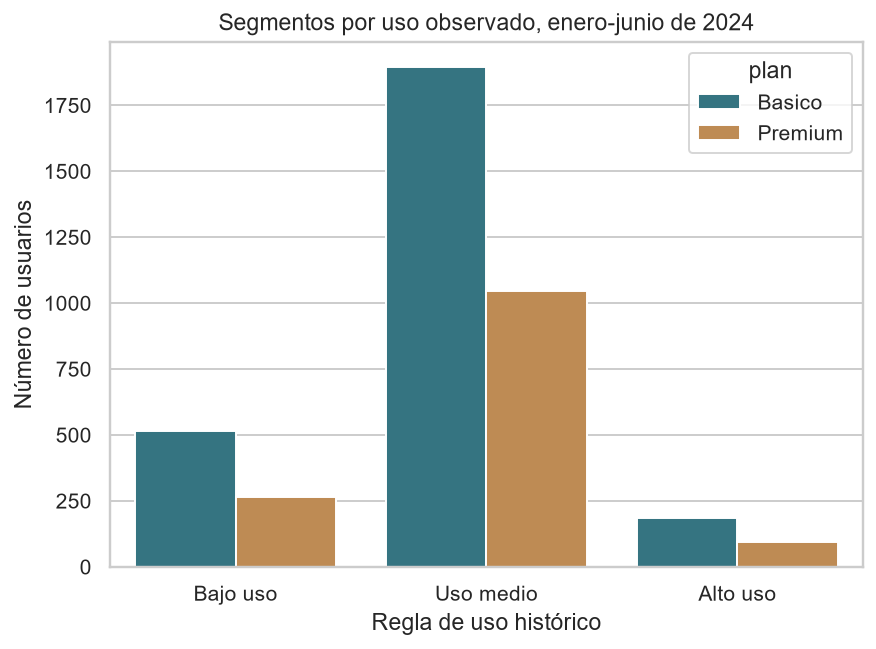

grupo_uso,Alto uso,Bajo uso,Uso medio
plan,,,
Basico,7.13,19.85,73.03
Premium,6.62,18.93,74.45


In [41]:
ax = sns.countplot(data=user_profile,x='grupo_uso',hue='plan',palette=PALETA,
                   order=['Bajo uso','Uso medio','Alto uso'])
ax.set(title='Segmentos por uso observado, enero-junio de 2024',
       xlabel='Regla de uso histórico',ylabel='Número de usuarios')
plt.tight_layout(); plt.show()
display(pd.crosstab(user_profile['plan'],user_profile['grupo_uso'],normalize='index').mul(100).round(2))

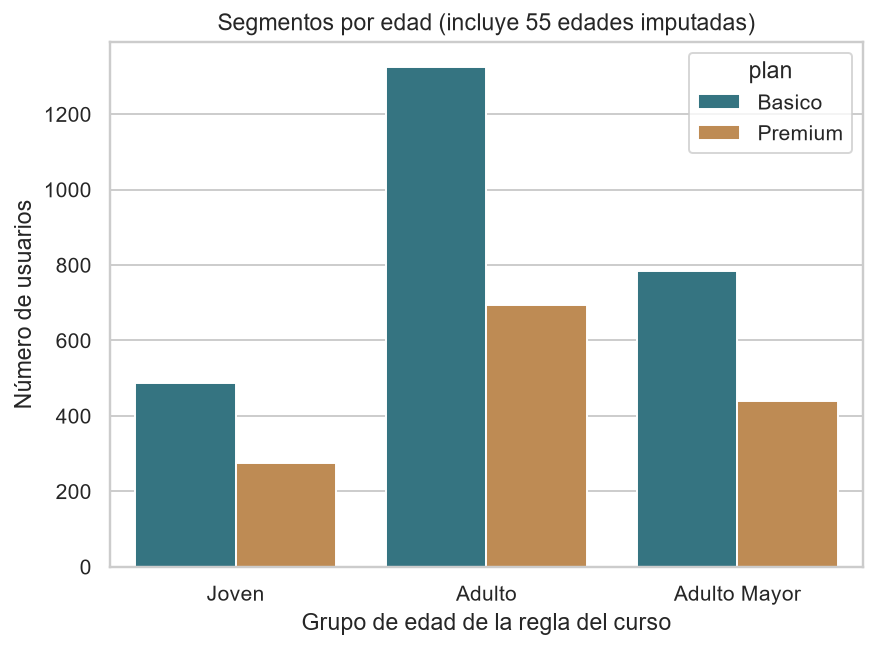

,cant_mensajes,cant_llamadas,cant_minutos_llamada
grupo_edad_validado,,,
Adulto,5.535,4.479,22.708
Adulto Mayor,5.478,4.495,22.743
Edad por validar,5.709,4.382,23.599
Joven,5.518,4.416,23.089


cant_mensajes        cant_llamadas        cant_minutos_llamada        
                       count   mean         count   mean                count    mean
pais_inferido                                                                        
Colombia                1848  5.531          1848  4.490                 1848  22.879
México                  1587  5.475          1587  4.448                 1587  22.860
Sin determinar           565  5.588           565  4.471                  565  22.393

In [42]:
ax = sns.countplot(data=user_profile,x='grupo_edad',hue='plan',palette=PALETA,
                   order=['Joven','Adulto','Adulto Mayor'])
ax.set(title='Segmentos por edad (incluye 55 edades imputadas)',
       xlabel='Grupo de edad de la regla del curso',ylabel='Número de usuarios')
plt.tight_layout(); plt.show()
display(user_profile.groupby('grupo_edad_validado')[columnas_uso].mean().round(3))
display(user_profile.groupby('pais_inferido')[columnas_uso].agg(['count','mean']).round(3))

## 7. Análisis ejecutivo

Las conclusiones siguientes son descriptivas del archivo disponible. Las recomendaciones son propuestas por validar con información de negocio y una prueba controlada.

### Resultados y decisiones

**Calidad.** Se conservan los 4,000 usuarios y se analizan 39,950 eventos fechados. Se apartan 50 sin fecha; hay 55 edades imputadas, 565 ciudades sin determinar, 40 altas fuera de corte y 466 bajas cuyo formato requiere validación. Se corrigen 28 medidas que no corresponden al tipo de evento.

**Uso observado.** Se registran 22,068 mensajes, 17,882 llamadas y 91,212.18 minutos. 1 usuario no tiene actividad fechada en esta extracción. Los grupos son: 781 de bajo uso, 2,941 de uso medio y 278 de alto uso. Incluir los eventos sin fecha cambia la clasificación de 2 usuarios.

**Edad.** Con edades válidas hay 760 jóvenes, 1,963 adultos y 1,222 adultos mayores; 55 quedan por validar. Los minutos medios son 23.09 en jóvenes, 22.71 en adultos y 22.74 en adultos mayores. Son diferencias descriptivas pequeñas en esta extracción y no justifican por sí solas una oferta distinta por edad.

**Valores extremos.** 157 usuarios presentan al menos una métrica de uso señalada por IQR. Se conservan y se propone revisar su trazabilidad; un extremo no demuestra fraude.

**Limitación temporal relevante.** Hay 10,451 eventos anteriores a la fecha de alta registrada, correspondientes a 1,302 usuarios. El anexo muestra la sensibilidad. Esta incoherencia debe resolverse antes de medir exposición, abandono o migraciones individuales.

**Propuestas comerciales.** Evaluar una oferta flexible para el grupo de bajo uso y revisar las necesidades de los usuarios de alto uso. Comparar el consumo de cada mes con los beneficios mensuales antes de sugerir una migración. Básico representa el 64.875% de los usuarios y Premium el 35.125%; el mayor volumen de registros del primero no prueba mayor intensidad individual. Los clientes Premium y de uso alto son candidatos a estudiar, pero no se afirma que sean los más rentables: faltan costos, ingresos efectivos y uso de datos móviles.

**Siguiente validación.** Confirmar cobertura de la extracción, unidad de las bajas, fechas de alta e historial de planes. Probar las propuestas con un piloto y medir aceptación, satisfacción e ingresos netos; no se promete una mejora con este análisis descriptivo.

## 8. Publicación y reproducción

El repositorio incluye este notebook, documentación, resultados agregados y gráficas. Los CSV se obtienen con acceso autorizado al curso y se colocan en `data/`. Reiniciar el entorno y ejecutar las celdas en orden reproduce el análisis.

Repositorio del proyecto: https://github.com/jluisrq5/connectatel-analysis

## Anexo. Auditoría temporal, consumo mensual y comprobaciones

Se añade una revisión de coherencia entre altas y actividad, la comparación mensual con beneficios del catálogo y la sensibilidad de los eventos sin fecha. Los datos no contienen consumo de GB ni historial de cambios de plan; no se estima facturación completa ni rentabilidad.

In [43]:
# Auditoría temporal y análisis mensual para no comparar seis meses con un plan mensual.
eventos_auditados = usage_2024.merge(users[['user_id','reg_date_original']],
    on='user_id',how='left',validate='many_to_one')
eventos_auditados['antes_del_alta'] = eventos_auditados['date'] < eventos_auditados['reg_date_original']
print('Eventos fechados anteriores al alta registrada:', eventos_auditados['antes_del_alta'].sum())
print('Usuarios afectados:', eventos_auditados.loc[eventos_auditados['antes_del_alta'],'user_id'].nunique())

mensual = usage_2024.assign(mes=usage_2024['date'].dt.to_period('M')).groupby(['user_id','mes']).agg(
    mensajes=('is_text','sum'),llamadas=('is_call','sum'),minutos=('duration','sum')).reset_index()
mensual = mensual.merge(user_profile[['user_id','plan','minutes_included','messages_included']],
    on='user_id',how='left',validate='many_to_one')
mensual['exceso_minutos'] = mensual['minutos'] > mensual['minutes_included']
mensual['exceso_mensajes'] = mensual['mensajes'] > mensual['messages_included']
resumen_mensual = mensual.groupby('plan').agg(meses_con_eventos=('user_id','size'),
    media_minutos=('minutos','mean'),mediana_minutos=('minutos','median'),
    media_mensajes=('mensajes','mean'),excesos_minutos=('exceso_minutos','sum'),
    excesos_mensajes=('exceso_mensajes','sum'))
display(resumen_mensual.round(3))
print('Los meses sin eventos no se interpretan como meses activos con consumo cero.')

# Cuánto cambia la clasificación si se incluyen los eventos sin fecha.
todos = usage.assign(is_text=usage['type'].eq('text').astype(int),
    is_call=usage['type'].eq('call').astype(int)).groupby('user_id').agg(
    llamadas=('is_call','sum'),mensajes=('is_text','sum'))
todos = user_profile[['user_id','grupo_uso']].merge(todos,on='user_id',how='left',validate='one_to_one').fillna({'llamadas':0,'mensajes':0})
todos['grupo_con_sin_fecha'] = todos.apply(lambda r:clasificar_uso(r['llamadas'],r['mensajes']),axis=1)
print('Usuarios que cambian de segmento al incluir eventos sin fecha:',
      todos['grupo_con_sin_fecha'].ne(todos['grupo_uso']).sum())

# Sensibilidad de minutos: solo eventos que no anteceden al alta registrada.
consistentes = eventos_auditados.loc[~eventos_auditados['antes_del_alta']]
print('Eventos temporalmente consistentes:',len(consistentes))
display(consistentes.groupby('type').agg(eventos=('id','size'),minutos=('duration','sum')).round(3))
assert len(usage_2024)+len(usage_sin_fecha)==len(usage_original)
assert user_profile['grupo_uso'].value_counts().sum()==len(users)
assert user_profile['grupo_edad'].value_counts().sum()==len(users)
print('Comprobaciones finales completadas sin errores.')

Eventos fechados anteriores al alta registrada: 10451
Usuarios afectados: 1302
Los meses sin eventos no se interpretan como meses activos con consumo cero.
Usuarios que cambian de segmento al incluir eventos sin fecha: 2
Eventos temporalmente consistentes: 29499
Comprobaciones finales completadas sin errores.


,meses_con_eventos,media_minutos,mediana_minutos,media_mensajes,excesos_minutos,excesos_mensajes
plan,,,,,,
Basico,12594,4.647,1.91,1.137,9,0
Premium,6843,4.776,1.96,1.132,0,0


,eventos,minutos
type,,
call,13163,66754.12
text,16336,0.00
